In [ ]:
# MiniProject 1 - Word Frequency Analysis

In [ ]:
## Question

I wanted to compare word frequencies between F. Colburn Adams and Robert Louis Stevenson.

I used two books from F. Colburn Adams and one book from Robert Louis Stevenson:

In [ ]:
**F.Colburn Adams**

- *Manuel Pereira; Or, The Sovereign Rule of South Carolina*
- *Our World; Or, the Slaveholder's Daughter*

**Robert Louis Stevenson**

- *Treasure Island*

I wanted to compare the two works by F. Colburn Adams first, then compare Adams's vocabulary with Stevenson's vocabulary to see if there were words that one author used noticeably more often than the other.


In [ ]:
## Approach

I downloaded the books as plain text from Project Gutenberg. I cleaned the text, converted the text to lowercase, and split it into individual words.

I removed common stop words so that words such as "the" and "and" would not dominate the results.

Since the books have different lengths, I compared relative word frequencies instead of only comparing raw word counts.

I then compared:

1. *Manuel Pereira* and *Our World* with each other.
2. The word frequencies of F. Colburn Adams's works with *Treasure Island* by Robert Louis Stevenson.
3. The words that were used more frequently by one author than the other.

In [ ]:
#Import the libraries

In [1]:
import requests
import re
import nltk
import matplotlib.pyplot as plt

from bs4 import BeautifulSoup
from nltk.probability import FreqDist

In [2]:
!pip install requests beautifulsoup4 nltk matplotlib

Defaulting to user installation because normal site-packages is not writeable


In [ ]:
# Define three books

In [3]:
books = {
    "Manuel Pereira": "https://www.gutenberg.org/cache/epub/4680/pg4680.txt",
    "Our World": "https://www.gutenberg.org/cache/epub/4677/pg4677.txt",
    "Treasure Island": "https://www.gutenberg.org/cache/epub/120/pg120.txt"
}

In [ ]:
# Download the books

In [4]:
texts = {}

for title, url in books.items():
    response = requests.get(url)
    response.raise_for_status()
    texts[title] = response.text

print("Books downloaded successfully!")

Books downloaded successfully!


In [5]:
texts = {}

for title, url in books.items():
    response = requests.get(url)
    response.raise_for_status()
    texts[title] = response.text

print("Books downloaded successfully!")

Books downloaded successfully!


In [6]:
for title, text in texts.items():
    print(title, ":", len(text), "characters")

Manuel Pereira : 513951 characters
Our World : 1347945 characters
Treasure Island : 391669 characters


In [ ]:
# Clean the text

In [7]:
def clean_text(text):
    # Convert everything to lowercase
    text = text.lower()
    
    # Keep only alphabetic characters and spaces
    text = re.sub(r"[^a-z\s]", " ", text)
    
    # Remove extra spaces
    text = re.sub(r"\s+", " ", text)
    
    return text.strip()

In [8]:
cleaned_texts = {}

for title, text in texts.items():
    cleaned_texts[title] = clean_text(text)

print("Text cleaning complete!")

Text cleaning complete!


In [ ]:
# Turn the text into words

In [9]:
tokens = {}

for title, text in cleaned_texts.items():
    tokens[title] = text.split()

for title, words in tokens.items():
    print(title, ":", len(words), "words")

Manuel Pereira : 91128 words
Our World : 235627 words
Treasure Island : 73537 words


In [ ]:
# Calculate word frequencies

In [10]:
frequency_distributions = {}

for title, words in tokens.items():
    frequency_distributions[title] = FreqDist(words)

In [11]:
for title, freq_dist in frequency_distributions.items():
    print("\n", title)
    print(freq_dist.most_common(20))


 Manuel Pereira
[('the', 6095), ('and', 2980), ('to', 2733), ('of', 2719), ('a', 2372), ('in', 1508), ('he', 1277), ('his', 1264), ('that', 1050), ('it', 892), ('for', 854), ('was', 843), ('with', 814), ('i', 734), ('you', 733), ('as', 712), ('s', 657), ('him', 649), ('we', 534), ('be', 509)]

 Our World
[('the', 14591), ('of', 7238), ('and', 6413), ('to', 5778), ('a', 5591), ('his', 4258), ('in', 3601), ('he', 3508), ('is', 2439), ('with', 2346), ('it', 2290), ('that', 2144), ('her', 1936), ('s', 1908), ('as', 1845), ('for', 1746), ('i', 1582), ('on', 1306), ('be', 1271), ('him', 1242)]

 Treasure Island
[('the', 4600), ('and', 2956), ('i', 1974), ('a', 1814), ('of', 1807), ('to', 1606), ('was', 1138), ('you', 1048), ('in', 1034), ('he', 939), ('that', 935), ('it', 793), ('had', 739), ('with', 665), ('his', 653), ('as', 636), ('my', 623), ('for', 615), ('s', 615), ('on', 527)]


In [ ]:
# Remove common words

In [12]:
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /home/bxy539/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [13]:
from nltk.corpus import stopwords

stop_words = set(stopwords.words('english'))

In [14]:
filtered_tokens = {}

for title, words in tokens.items():
    filtered_tokens[title] = [
        word for word in words
        if word not in stop_words
    ]

In [15]:
filtered_frequencies = {}

for title, words in filtered_tokens.items():
    filtered_frequencies[title] = FreqDist(words)

In [16]:
for title, freq_dist in filtered_frequencies.items():
    print("\n", title)
    print(freq_dist.most_common(20))


 Manuel Pereira
[('said', 425), ('captain', 395), ('upon', 383), ('man', 285), ('would', 266), ('manuel', 247), ('little', 219), ('one', 210), ('law', 201), ('south', 192), ('old', 176), ('good', 172), ('carolina', 169), ('charleston', 148), ('well', 143), ('get', 139), ('made', 135), ('mr', 132), ('jail', 131), ('like', 130)]

 Our World
[('good', 647), ('man', 613), ('upon', 608), ('would', 586), ('one', 559), ('old', 555), ('mr', 509), ('hand', 483), ('says', 482), ('ye', 426), ('must', 393), ('marston', 389), ('like', 378), ('make', 377), ('little', 358), ('may', 356), ('great', 352), ('right', 345), ('property', 341), ('nigger', 323)]

 Treasure Island
[('said', 323), ('one', 282), ('man', 262), ('captain', 236), ('silver', 224), ('like', 207), ('doctor', 175), ('could', 175), ('would', 169), ('us', 167), ('well', 156), ('upon', 154), ('see', 145), ('time', 131), ('good', 129), ('old', 123), ('hand', 122), ('still', 120), ('two', 117), ('ship', 117)]


In [ ]:
# Visualizing Word Frequencies

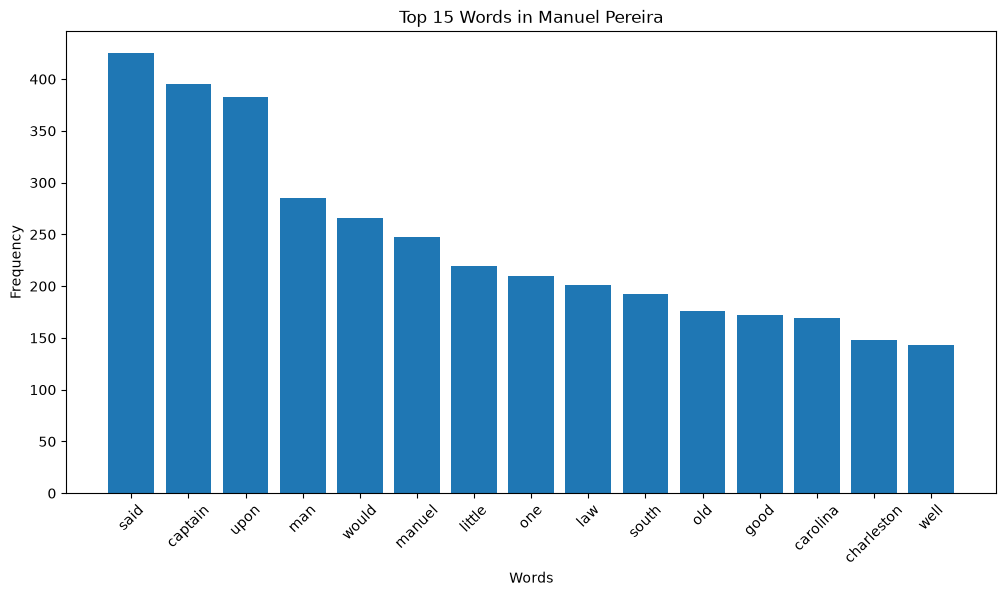

In [17]:
title = "Manuel Pereira"

top_words = filtered_frequencies[title].most_common(15)

words = [item[0] for item in top_words]
counts = [item[1] for item in top_words]

plt.figure(figsize=(12, 6))
plt.bar(words, counts)

plt.title("Top 15 Words in Manuel Pereira")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.xticks(rotation=45)

plt.show()

In [ ]:
# Compare Adams's two books

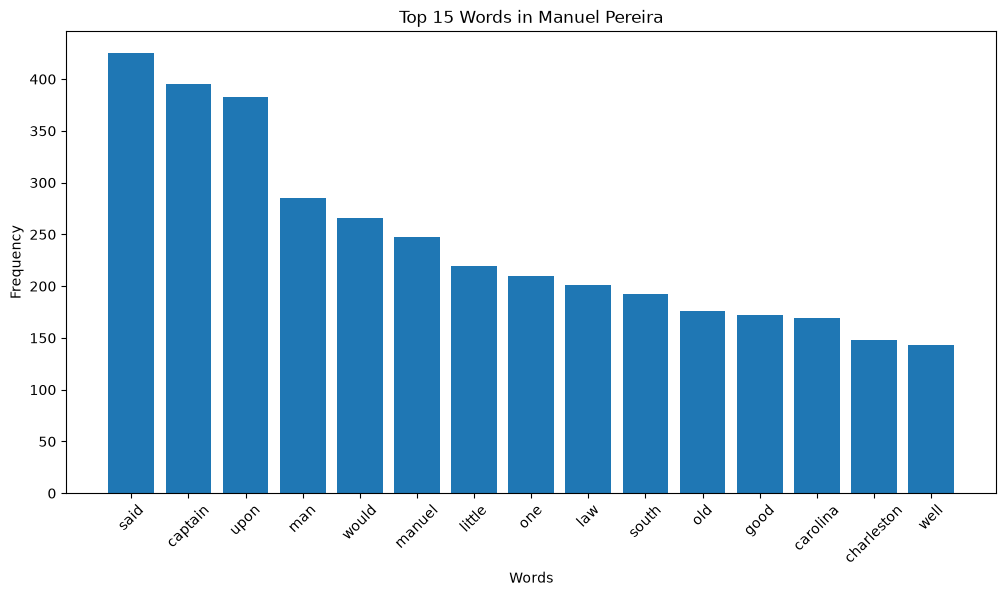

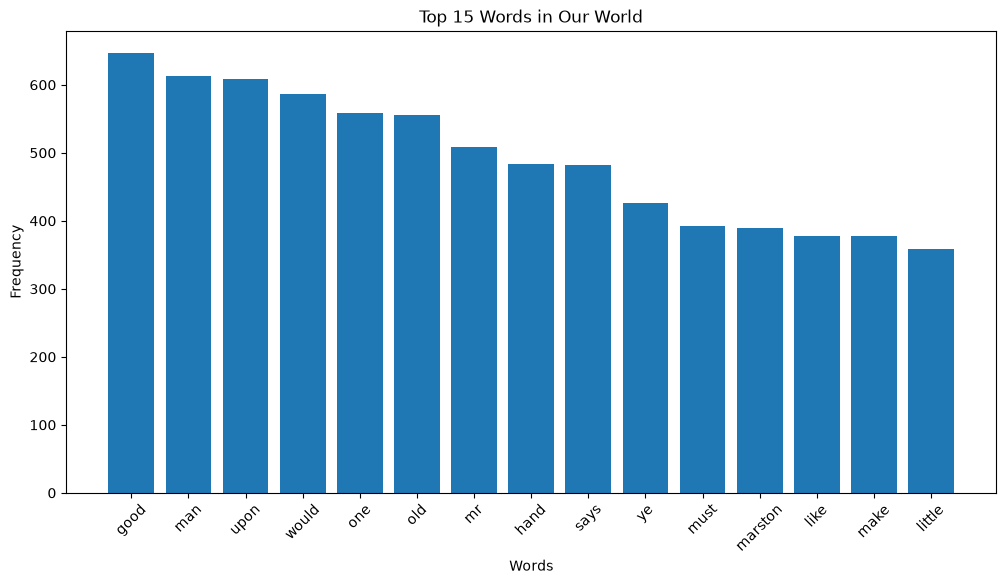

In [18]:
adams_books = ["Manuel Pereira", "Our World"]

for title in adams_books:
    top_words = filtered_frequencies[title].most_common(15)
    
    words = [item[0] for item in top_words]
    counts = [item[1] for item in top_words]
    
    plt.figure(figsize=(12, 6))
    plt.bar(words, counts)
    
    plt.title(f"Top 15 Words in {title}")
    plt.xlabel("Words")
    plt.ylabel("Frequency")
    plt.xticks(rotation=45)
    
    plt.show()

In [ ]:
# Compare Adams vs. Stevenson

In [19]:
authors = {
    "F. Colburn Adams": ["Manuel Pereira", "Our World"],
    "Robert Louis Stevenson": ["Treasure Island"]
}

In [20]:
adams_words = (
    filtered_tokens["Manuel Pereira"] +
    filtered_tokens["Our World"]
)

stevenson_words = filtered_tokens["Treasure Island"]

adams_freq = FreqDist(adams_words)
stevenson_freq = FreqDist(stevenson_words)

In [21]:
print("Top Adams words:")
print(adams_freq.most_common(20))

print("\nTop Stevenson words:")
print(stevenson_freq.most_common(20))

Top Adams words:
[('upon', 991), ('man', 898), ('would', 852), ('good', 819), ('one', 769), ('old', 731), ('mr', 641), ('said', 585), ('little', 577), ('hand', 565), ('ye', 540), ('must', 519), ('like', 508), ('make', 507), ('says', 498), ('may', 476), ('well', 461), ('right', 441), ('nigger', 437), ('much', 422)]

Top Stevenson words:
[('said', 323), ('one', 282), ('man', 262), ('captain', 236), ('silver', 224), ('like', 207), ('doctor', 175), ('could', 175), ('would', 169), ('us', 167), ('well', 156), ('upon', 154), ('see', 145), ('time', 131), ('good', 129), ('old', 123), ('hand', 122), ('still', 120), ('two', 117), ('ship', 117)]


In [ ]:
# Find words preferred by each author

In [22]:
def relative_frequency(freq_dist):
    total_words = freq_dist.N()
    
    return {
        word: count / total_words
        for word, count in freq_dist.items()
    }

In [23]:
adams_relative = relative_frequency(adams_freq)
stevenson_relative = relative_frequency(stevenson_freq)

In [24]:
word_differences = []

for word in adams_relative:
    if word in stevenson_relative:
        difference = adams_relative[word] - stevenson_relative[word]
        word_differences.append((word, difference))

word_differences.sort(key=lambda x: x[1], reverse=True)

print("Words relatively more common in Adams:")
print(word_differences[:20])

Words relatively more common in Adams:
[('ye', 0.0031524074736823354), ('law', 0.0023244180890234487), ('property', 0.0021165152178809345), ('slave', 0.002078809195684297), ('mr', 0.0020281869178012356), ('feelings', 0.0018954765753111536), ('master', 0.0018346175046260102), ('harry', 0.0015787395314530487), ('make', 0.0015339765381431887), ('upon', 0.0015106330142049453), ('south', 0.001378490851323457), ('state', 0.0013487231099440385), ('r', 0.001278256753388239), ('good', 0.0011974244559034503), ('city', 0.0011865904432016674), ('children', 0.0011621460938185818), ('whose', 0.0011591535008388387), ('makes', 0.0011031142166048865), ('negroes', 0.0010460354342489244), ('child', 0.0010349786590656764)]


In [25]:
word_differences.sort(key=lambda x: x[1])

print("Words relatively more common in Stevenson:")
print(word_differences[:20])

Words relatively more common in Stevenson:
[('silver', -0.006556570461821941), ('said', -0.005958662072735519), ('doctor', -0.0050797340333575474), ('captain', -0.00442354917537514), ('one', -0.003624068518232819), ('could', -0.003197519130859946), ('ship', -0.0030133665281056373), ('like', -0.0030053669199655852), ('still', -0.0029980258590480663), ('cried', -0.0029790308030475986), ('sea', -0.0029482235635461705), ('jim', -0.0028497843720506743), ('us', -0.0028208366130524206), ('squire', -0.0027681353389253415), ('island', -0.0025424028112906545), ('last', -0.0025235659437081986), ('began', -0.0024588006833075877), ('sir', -0.0023506283045551506), ('john', -0.0022471175238358925), ('man', -0.00224541947849135)]


In [ ]:
## What Problems Did I Encounter?

One of the main problems I encountered was cleaning the Project Gutenberg text files. The files include additional information, such as the Project Gutenberg header and footer, which can affect the word frequency analysis.

Another challenge was that common words such as "the," "and," and "of" appeared very frequently in the results. To make the analysis more meaningful, I removed common English stop words.

The books also have different lengths, which made it difficult to compare raw word counts directly. To solve this problem, I used relative word frequencies so that the results could be compared more fairly.

Another challenge was determining which words were actually preferred by one author instead of simply appearing more often because one book was longer or focused on a different topic.

In [ ]:
## What Results Did I Get?

The analysis showed differences and similarities in the vocabulary used by F. Colburn Adams and Robert Louis Stevenson.

When comparing *Manuel Pereira* and *Our World*, I found that some high-frequency words appeared in both books, while other words were more common in one book than the other.

When comparing F. Colburn Adams's works with *Treasure Island* by Robert Louis Stevenson, the results showed differences in word frequency and vocabulary usage between the authors.

The relative word frequency analysis also helped identify words that were used more frequently by one author than the other.

The visualizations made it easier to compare the vocabulary patterns and identify differences between the books and authors.

In [ ]:
## What New Ideas Did This Generate?

This analysis generated several ideas for future research.

One possible extension would be to compare more books written by each author to determine whether the vocabulary patterns found in this project are consistent across their other works.

Another idea would be to analyze how vocabulary changes throughout a single book by comparing different chapters or sections.

I could also investigate the frequency of a specific word, such as "would," and use a binomial distribution to determine whether the frequency of that word differs significantly between books or authors.

Another possible extension would be to use sentiment analysis to compare the emotional tone of the books or identify how the tone changes throughout each work.